In [1]:
!pip install -q gradio pillow-heif

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import time

from PIL import Image
from pillow_heif import register_heif_opener

register_heif_opener()

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [3]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving Equals.zip to Equals.zip
Saving Minus.zip to Minus.zip
Saving Plus.zip to Plus.zip
Uploaded files: ['Equals.zip', 'Minus.zip', 'Plus.zip']


In [4]:
import os
import zipfile
import shutil

zip_files = {
    "Plus.zip": "plus",
    "Minus.zip": "minus",
    "Equals.zip": "equals"
}

base_dir = "/content/dataset"

if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

for zip_name, class_name in zip_files.items():
    target = os.path.join(base_dir, class_name)
    os.makedirs(target, exist_ok=True)

    with zipfile.ZipFile(zip_name, "r") as z:
        z.extractall(target)

    macosx = os.path.join(target, "__MACOSX")
    if os.path.exists(macosx):
        shutil.rmtree(macosx)

print("Dataset extracted and cleaned.")

Dataset extracted and cleaned.


In [5]:
from PIL import Image
from pillow_heif import register_heif_opener
from pathlib import Path

register_heif_opener()

folders = {
    "plus": "/content/dataset/plus/Plus",
    "minus": "/content/dataset/minus/Minus",
    "equals": "/content/dataset/equals/Equal"
}

for class_name, folder in folders.items():
    folder = Path(folder)

    heic_files = list(folder.glob("*.heic"))

    for file in heic_files:
        img = Image.open(file).convert("RGB")
        new_path = file.with_suffix(".jpg")
        img.save(new_path, "JPEG", quality=95)
        file.unlink()

    jpg_count = len(list(folder.glob("*.jpg")))
    print(f"{class_name}: {jpg_count} JPG images")

plus: 90 JPG images
minus: 99 JPG images
equals: 100 JPG images


In [6]:
from pathlib import Path
from collections import Counter

for class_name, folder in folders.items():
    folder = Path(folder)

    extensions = Counter(
        f.suffix.lower()
        for f in folder.iterdir()
        if f.is_file()
    )

    print(f"\n{class_name}:")
    print(extensions)
    print("Total files:", sum(extensions.values()))


plus:
Counter({'.jpg': 90, '.heic': 10})
Total files: 100

minus:
Counter({'.jpg': 99, '.heic': 1})
Total files: 100

equals:
Counter({'.jpg': 100})
Total files: 100


In [7]:
from pathlib import Path
from PIL import Image

for class_name, folder in folders.items():
    folder = Path(folder)

    for file in folder.iterdir():
        if file.is_file() and file.suffix.lower() == ".heic":
            img = Image.open(file).convert("RGB")
            new_path = file.with_suffix(".jpg")
            img.save(new_path, "JPEG", quality=95)
            file.unlink()

    jpg_count = len([
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() == ".jpg"
    ])

    print(f"{class_name}: {jpg_count} JPG images")

plus: 100 JPG images
minus: 100 JPG images
equals: 100 JPG images


In [8]:
import os
import shutil
import tensorflow as tf

final_dir = "/content/final_dataset"

if os.path.exists(final_dir):
    shutil.rmtree(final_dir)

os.makedirs(final_dir)

source_folders = {
    "plus": "/content/dataset/plus/Plus",
    "minus": "/content/dataset/minus/Minus",
    "equals": "/content/dataset/equals/Equal"
}

for class_name, source in source_folders.items():
    destination = os.path.join(final_dir, class_name)
    shutil.copytree(source, destination)

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    final_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    final_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print("Classes:", class_names)

Found 300 files belonging to 3 classes.
Using 240 files for training.
Found 300 files belonging to 3 classes.
Using 60 files for validation.
Classes: ['equals', 'minus', 'plus']


In [9]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10)
])

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Dataset pipeline ready.")

Dataset pipeline ready.


In [10]:
from tensorflow.keras import models, layers

base_model = tf.keras.applications.EfficientNetV2B0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

sota_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(3, activation="softmax")
])

sota_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

sota_model.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,083,667 (23.21 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 5,919,312 (22.58 MB)

In [11]:
history_sota = sota_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.6292 - loss: 0.8183 - val_accuracy: 0.8167 - val_loss: 0.4942
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.8792 - loss: 0.3850 - val_accuracy: 0.8500 - val_loss: 0.2979
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.9333 - loss: 0.2071 - val_accuracy: 0.9833 - val_loss: 0.0862
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.9667 - loss: 0.1306 - val_accuracy: 0.9833 - val_loss: 0.0903
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9750 - loss: 0.0996 - val_accuracy: 0.9833 - val_loss: 0.0674
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.9833 - loss: 0.0812 - val_accuracy: 0.9333 - val_loss: 0.0979
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.9875 - loss: 0.0498 - val_accuracy: 0.9833 - val_loss: 0.0590
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.9917 - loss: 0.0568 - val_accuracy: 0.9667 - val_loss:

Validation Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

      equals     1.0000    1.0000    1.0000        20
       minus     1.0000    1.0000    1.0000        22
        plus     1.0000    1.0000    1.0000        18

    accuracy                         1.0000        60
   macro avg     1.0000    1.0000    1.0000        60
weighted avg     1.0000    1.0000    1.0000        60



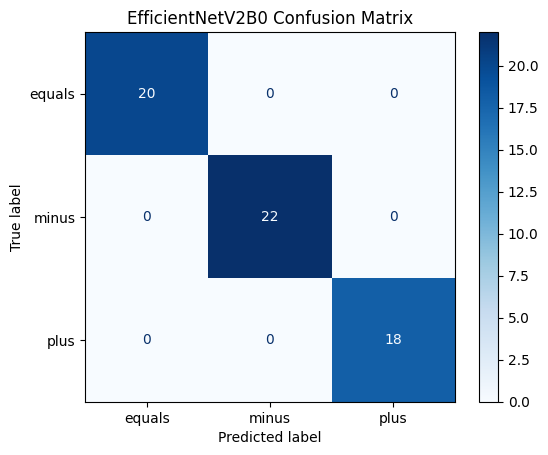

In [12]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = sota_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

accuracy = accuracy_score(y_true, y_pred)

print(f"Validation Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title("EfficientNetV2B0 Confusion Matrix")
plt.show()

In [13]:
from tensorflow.keras import layers, models
import tensorflow as tf

base_model_no_aug = tf.keras.applications.EfficientNetV2B0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model_no_aug.trainable = False

model_no_aug = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    base_model_no_aug,

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(3, activation="softmax")
])

model_no_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model without augmentation ready.")

Model without augmentation ready.


In [14]:
history_no_aug = model_no_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.7167 - loss: 0.6943 - val_accuracy: 0.9833 - val_loss: 0.2568
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.9583 - loss: 0.2086 - val_accuracy: 0.9833 - val_loss: 0.0843
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.9750 - loss: 0.1064 - val_accuracy: 1.0000 - val_loss: 0.0336
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.9833 - loss: 0.0746 - val_accuracy: 1.0000 - val_loss: 0.0195
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.9750 - loss: 0.0902 - val_accuracy: 1.0000 - val_loss: 0.0151
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.9792 - loss: 0.0532 - val_accuracy: 1.0000 - val_loss: 0.0137
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.9833 - loss: 0.0493 - val_accuracy: 1.0000 - val_loss: 0.0101
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.9875 - loss: 0.0479 - val_accuracy: 1.0000 - val_loss:

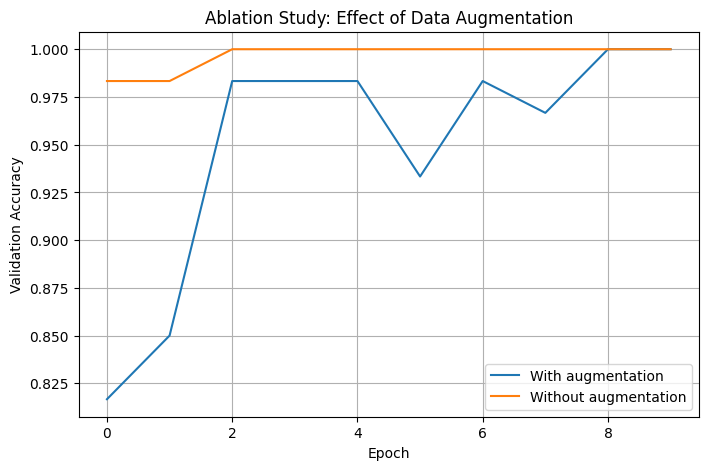

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_sota.history["val_accuracy"],
    label="With augmentation"
)

plt.plot(
    history_no_aug.history["val_accuracy"],
    label="Without augmentation"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Ablation Study: Effect of Data Augmentation")
plt.legend()
plt.grid()

plt.show()

In [16]:
for i, layer in enumerate(base_model.layers[-30:]):
    print(i - 30, layer.name, layer.__class__.__name__, layer.output.shape)


-30 block6g_dwconv2 DepthwiseConv2D (None, 7, 7, 1152)
-29 block6g_bn BatchNormalization (None, 7, 7, 1152)
-28 block6g_activation Activation (None, 7, 7, 1152)
-27 block6g_se_squeeze GlobalAveragePooling2D (None, 1152)
-26 block6g_se_reshape Reshape (None, 1, 1, 1152)
-25 block6g_se_reduce Conv2D (None, 1, 1, 48)
-24 block6g_se_expand Conv2D (None, 1, 1, 1152)
-23 block6g_se_excite Multiply (None, 7, 7, 1152)
-22 block6g_project_conv Conv2D (None, 7, 7, 192)
-21 block6g_project_bn BatchNormalization (None, 7, 7, 192)
-20 block6g_drop Dropout (None, 7, 7, 192)
-19 block6g_add Add (None, 7, 7, 192)
-18 block6h_expand_conv Conv2D (None, 7, 7, 1152)
-17 block6h_expand_bn BatchNormalization (None, 7, 7, 1152)
-16 block6h_expand_activation Activation (None, 7, 7, 1152)
-15 block6h_dwconv2 DepthwiseConv2D (None, 7, 7, 1152)
-14 block6h_bn BatchNormalization (None, 7, 7, 1152)
-13 block6h_activation Activation (None, 7, 7, 1152)
-12 block6h_se_squeeze GlobalAveragePooling2D (None, 1152)
-11 b

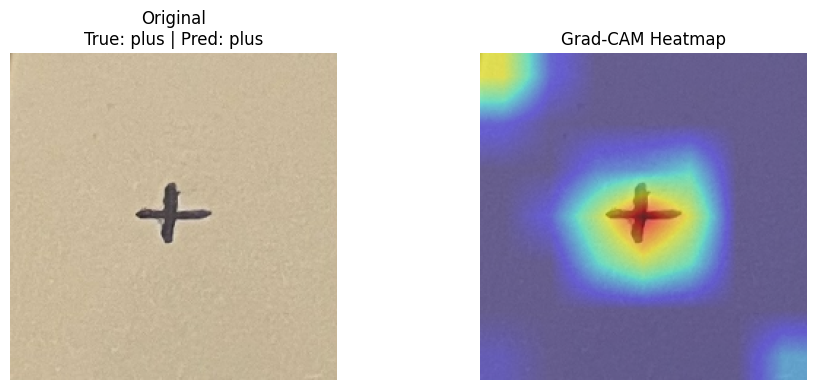

In [22]:
for images, labels in val_ds.take(1):
    sample_img = images[0:1]
    true_label = int(labels[0].numpy())
    break

heatmap, pred_class = make_gradcam_v2(sample_img)

pred_name = class_names[pred_class]
true_name = class_names[true_label]

heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

original = sample_img[0].numpy().astype("uint8")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title(f"Original\nTrue: {true_name} | Pred: {pred_name}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.5)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
import time
import numpy as np

for images, labels in val_ds.take(1):
    test_img = images[0:1]
    break

# Warm-up
for _ in range(5):
    _ = sota_model.predict(test_img, verbose=0)

times = []

for _ in range(30):
    start = time.perf_counter()

    _ = sota_model.predict(test_img, verbose=0)

    end = time.perf_counter()
    times.append((end - start) * 1000)

avg_latency = np.mean(times)

print(f"Average inference latency: {avg_latency:.2f} ms")
print(f"Device: Google Colab")


Average inference latency: 386.72 ms
Device: Google Colab


In [24]:
import gradio as gr
import numpy as np
import tensorflow as tf
import time
from PIL import Image
import matplotlib.cm as cm

def predict_with_gradcam(image):
    # Prepare image
    img = Image.fromarray(image).convert("RGB")
    img = img.resize((224, 224))

    img_array = np.array(img).astype("float32")
    batch = np.expand_dims(img_array, axis=0)

    # Measure inference time
    start = time.perf_counter()
    predictions = sota_model.predict(batch, verbose=0)
    end = time.perf_counter()

    latency = (end - start) * 1000

    pred_index = int(np.argmax(predictions[0]))
    pred_class = class_names[pred_index]
    confidence = float(predictions[0][pred_index])

    # Grad-CAM
    heatmap, _ = make_gradcam_v2(batch)

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    # Convert heatmap to RGB
    jet = cm.get_cmap("jet")
    colored_heatmap = jet(heatmap_resized)[:, :, :3]
    colored_heatmap = (colored_heatmap * 255).astype("uint8")

    original = np.array(img)

    overlay = (
        0.55 * original +
        0.45 * colored_heatmap
    ).astype("uint8")

    prediction_text = (
        f"Prediction: {pred_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )

    latency_text = (
        f"Inference latency: {latency:.2f} ms\n"
        f"Environment: Google Colab"
    )

    return prediction_text, overlay, latency_text

In [26]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/converted_dataset",
    "zip",
    "/content/final_dataset"
)

files.download("/content/converted_dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
demo = gr.Interface(
    fn=predict_with_gradcam,

    inputs=gr.Image(
        type="numpy",
        sources=["upload", "webcam"],
        label="Upload or take a photo of a symbol"
    ),

    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Image(label="Grad-CAM Explanation"),
        gr.Textbox(label="Latency")
    ],

    title="Handwritten Symbol Classifier",
    description="Upload or capture a handwritten +, - or = symbol."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b20c80352c6daeab16.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [27]:
sota_model.save("/content/efficientnetv2_symbol_classifier.keras")

print("Model saved!")

Model saved!


In [28]:
from google.colab import files

files.download("/content/efficientnetv2_symbol_classifier.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>